# Bank Marketing Campaign Response Analysis & Prediction

## 2. Exploratory Data Analysis (EDA)

### Objective

Explore customer characteristics and marketing campaign information to identify patterns associated with term deposit subscriptions.

### Key Questions

* What proportion of customers subscribed to a term deposit?
* What are the characteristics of the customers in this dataset?
* Does the subscription rate vary across job categories, education levels, or marital statuses?
* How are customer age, account balance, and campaign contacts distributed?
* Which patterns could help the bank improve its marketing strategy?

### Tools

Python, Pandas, Matplotlib, and Seaborn.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
df=pd.read_csv('../data/bank-full.csv',sep=';')


In [6]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [8]:
df.shape

(45211, 17)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [10]:
df['y'].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [11]:
response_percent=df['y'].value_counts(normalize=True)*100
print(response_percent)

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


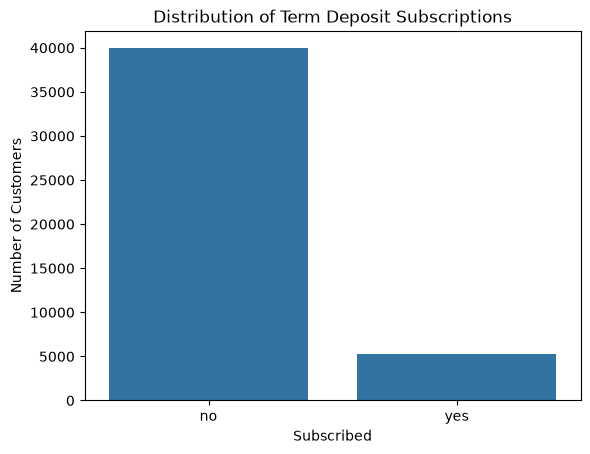

In [14]:
sns.countplot(data=df, x='y')
plt.title('Distribution of Term Deposit Subscriptions')
plt.xlabel('Subscribed')
plt.ylabel('Number of Customers')

plt.show()

In [16]:
df.select_dtypes(include='number').columns

Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='str')

In [17]:
df[['age','balance','campaign']].describe()

,age,balance,campaign
count,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,2.763841
std,10.618762,3044.765829,3.098021
min,18.000000,-8019.000000,1.000000
25%,33.000000,72.000000,1.000000
50%,39.000000,448.000000,2.000000
75%,48.000000,1428.000000,3.000000
max,95.000000,102127.000000,63.000000


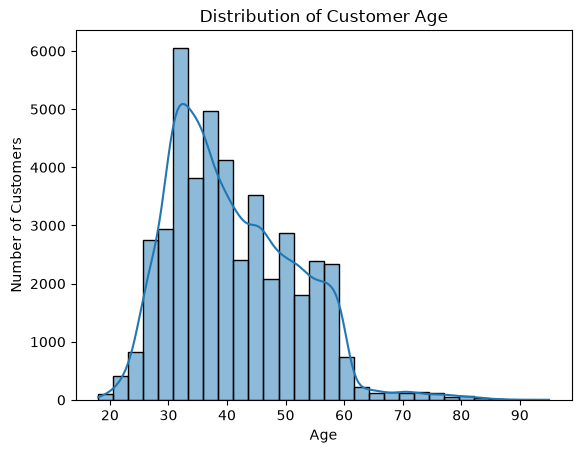

In [30]:
sns.histplot(data=df, x='age',bins=30, kde=True)

plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

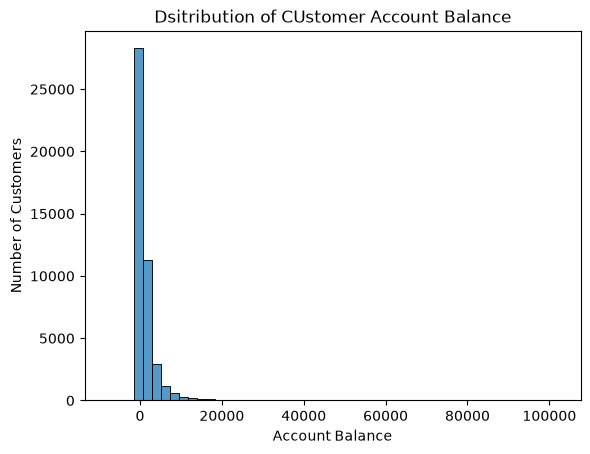

In [39]:
sns.histplot(data=df, x='balance',bins=50)
    
plt.title('Dsitribution of CUstomer Account Balance')
plt.xlabel('Account Balance')
plt.ylabel('Number of Customers')

plt.show()

In [36]:
df['balance'].describe()

count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
25%          72.000000
50%         448.000000
75%        1428.000000
max      102127.000000
Name: balance, dtype: float64

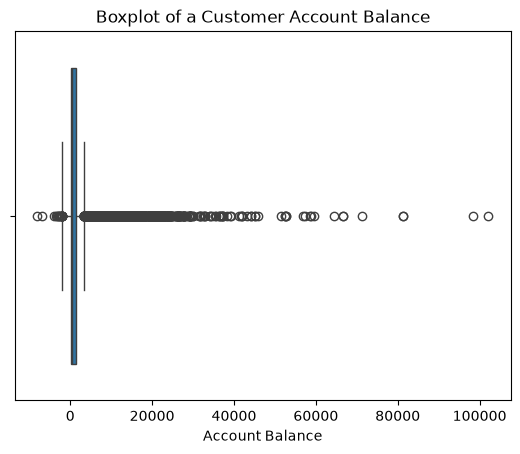

In [42]:
sns.boxplot(data=df, x='balance')

plt.title('Boxplot of a Customer Account Balance')
plt.xlabel('Account Balance')

plt.show()

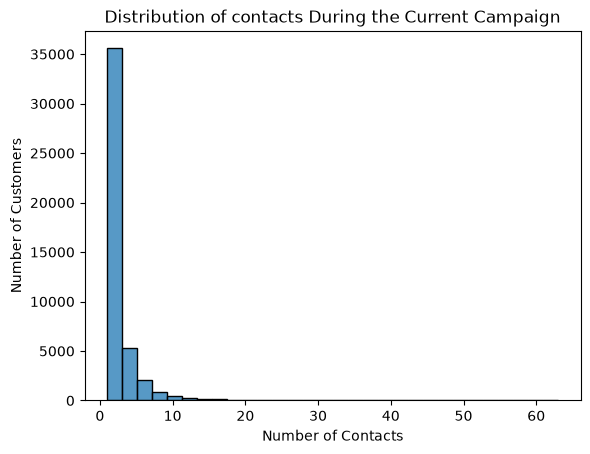

In [46]:
sns.histplot(data=df, x='campaign',bins=30)

plt.title("Distribution of contacts During the Current Campaign")
plt.xlabel('Number of Contacts')
plt.ylabel('Number of Customers')

plt.show()

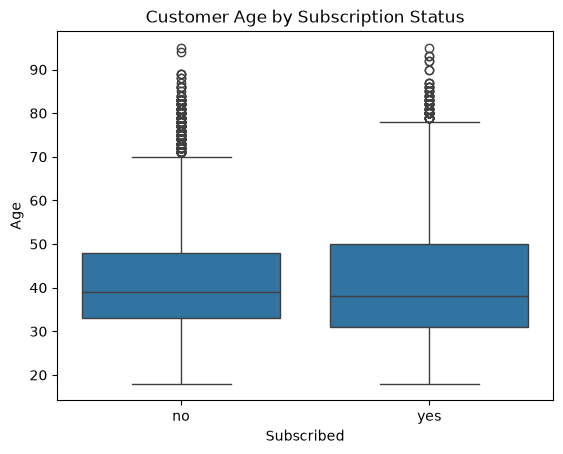

In [48]:
sns.boxplot(data=df, x='y', y='age')

plt.title("Customer Age by Subscription Status")
plt.xlabel("Subscribed")
plt.ylabel("Age")

plt.show()


In [54]:
df['y'].describe()

count     45211
unique        2
top          no
freq      39922
Name: y, dtype: object

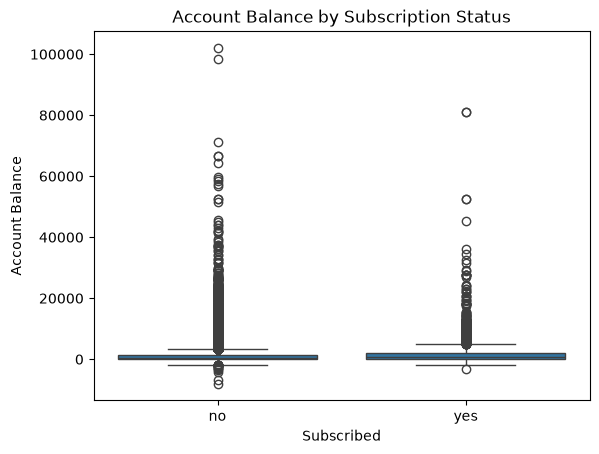

In [50]:
sns.boxplot(data=df, x="y", y="balance")

plt.title("Account Balance by Subscription Status")
plt.xlabel("Subscribed")
plt.ylabel("Account Balance")

plt.show()

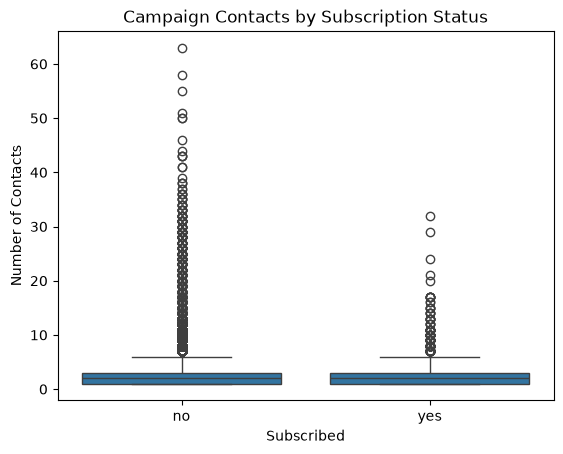

In [52]:
sns.boxplot(data=df, x="y", y="campaign")

plt.title("Campaign Contacts by Subscription Status")
plt.xlabel("Subscribed")
plt.ylabel("Number of Contacts")

plt.show()

In [55]:
df.groupby('y')[['age','balance','campaign']].median()

,age,balance,campaign
y,,,
no,39.0,417.0,2.0
yes,38.0,733.0,2.0


### Key Findings: Numerical Variables

1. **Age:** The median age is 39 years for non-subscribers and 38 years for subscribers. This suggests that the typical age is similar across the two groups.

2. **Account Balance:** The median balance is 733 among subscribers, compared with 417 among non-subscribers. This difference warrants further investigation to determine whether subscription rates vary across balance groups.

3. **Campaign Contacts:** Both groups have a median of two contacts. However, the box plots show that the distributions contain high-contact observations, particularly among non-subscribers.


